In [6]:
from pathlib import Path
import geopandas as gpd

caminho = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
print(Path.exists(caminho))

True


In [7]:
pref_bairro = gpd.read_file(caminho)
pref_bairro.head()

/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.10/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,PREF_BAIRR,COD_PBR,ID,QTD_BAIRRO,area,geometry
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,4,17,94380440.97,"MULTIPOLYGON (((563183.372 8565464.348, 563137..."
1,Prefeitura-bairro X - Valéria,X,10,4,25325166.31,"MULTIPOLYGON (((560318.999 8574966.432, 560166..."
2,Prefeitura-bairro V - Cidade Baixa,V,5,14,8132459.00,"MULTIPOLYGON (((553769.31 8569249.552, 553767...."
3,Prefeitura-bairro III - Cajazeiras,III,3,17,22160586.15,"MULTIPOLYGON (((566822.94 8573201.26, 566811.8..."
4,Prefeitura-bairro IX - Pau da Lima,IX,9,13,19905726.69,"MULTIPOLYGON (((563789.494 8569538.91, 563559...."


In [28]:
print("Dimensões: ",pref_bairro.shape)
print("Colunas: ",pref_bairro.columns.to_frame())
print("Sistema de coordenadas: ", pref_bairro.crs)
print("Tipos de geometria: ")
print(pref_bairro.geometry.geom_type.value_counts())

pref_bairro[["PREF_BAIRR", "COD_PBR", "QTD_BAIRRO"]]

Dimensões:  (10, 6)
Colunas:                       0
PREF_BAIRR  PREF_BAIRR
COD_PBR        COD_PBR
ID                  ID
QTD_BAIRRO  QTD_BAIRRO
area              area
geometry      geometry
Sistema de coordenadas:  EPSG:31984
Tipos de geometria: 
MultiPolygon    10
Name: count, dtype: int64


,PREF_BAIRR,COD_PBR,QTD_BAIRRO
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,17
1,Prefeitura-bairro X - Valéria,X,4
2,Prefeitura-bairro V - Cidade Baixa,V,14
3,Prefeitura-bairro III - Cajazeiras,III,17
4,Prefeitura-bairro IX - Pau da Lima,IX,13
5,Prefeitura-bairro VII - Liberdade / São Caetano,VII,19
6,Prefeitura-bairro II - Subúrbio / Ilhas,II,19
7,Prefeitura-bairro VIII - Cabula / Tancredo Neves,VIII,22
8,Prefeitura-bairro VI - Barra / Pituba,VI,23
9,Prefeitura-bairro I - Centro / Brotas,I,23


In [12]:
print("Nomes ausentes:", pref_bairro["PREF_BAIRR"].isna().sum())
print("Nomes unicos: ", pref_bairro["PREF_BAIRR"].nunique())
print("Nomes duplicador: ", pref_bairro["PREF_BAIRR"].duplicated().sum())


print("\nGeometria ausente: ", pref_bairro.geometry.isna().sum())
print("Geometria vazio: ", pref_bairro.geometry.is_empty.sum())
print("Geometria invalidos: ", (~pref_bairro.geometry.is_valid).sum()) # Retirando o ~ e os (), retornaria todos o validos

Nomes ausentes: 0
Nomes unicos:  10
Nomes duplicador:  0

Geometria ausente:  0
Geometria vazio:  0
Geometria invalidos:  0


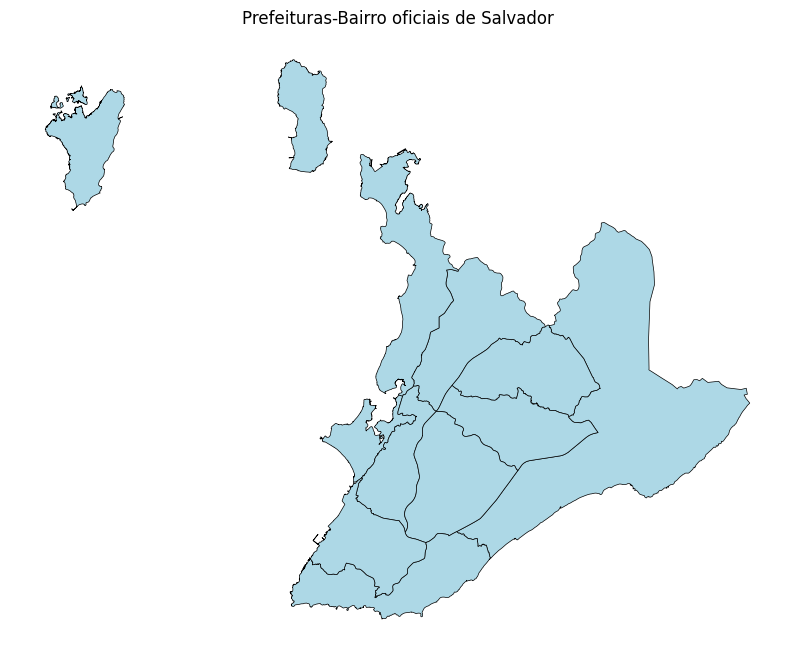

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize = (10,10))

pref_bairro.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    linewidth=0.5
)
ax.set_title("Prefeituras-Bairro oficiais de Salvador")
ax.set_axis_off()

plt.show()

In [58]:
piloto = pref_bairro.loc[pref_bairro["COD_PBR"] == "I"].copy()

piloto[["PREF_BAIRR","COD_PBR","QTD_BAIRRO"]]


,PREF_BAIRR,COD_PBR,QTD_BAIRRO
9,Prefeitura-bairro I - Centro / Brotas,I,23


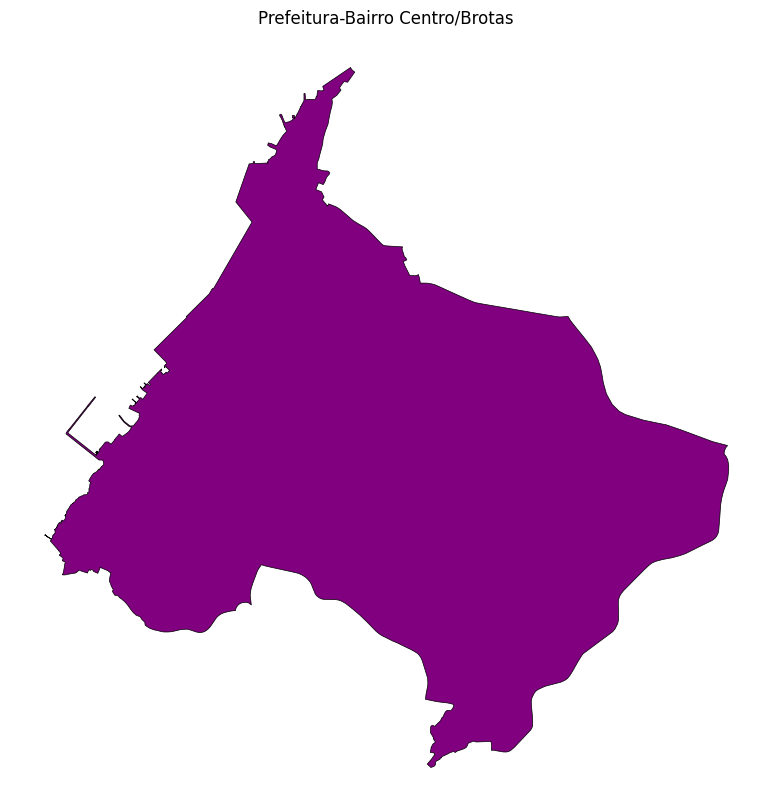

In [43]:
fig, ax = plt.subplots(figsize = (10,10))
piloto.plot(
    ax = ax,
    facecolor = "purple",
    edgecolor = "black",
    linewidth = 0.5
)
ax.set_title("Prefeitura-Bairro Centro/Brotas")
ax.set_axis_off()
plt.show()

In [50]:
caminho_bairros = Path("../dados/brutos/bairros/lei_9778_2024_bairros_a.gpkg")
# print(Path.exists(caminho_bairros)) Retorna um Boolean informando se o caminho "existe" ou não
bairros = gpd.read_file(caminho_bairros)
bairros.head()

,ID,NOME_BAIRRO,AREA,UNIDADE_AREA,INSTITUIDO_POR,ALTERADO_POR,geometry
0,115.0,Mangueira,282444.71,m²,9.278/2017,None,"MULTIPOLYGON Z (((554620.782 8571554.677 0, 55..."
1,25.0,Pituba,4239298.73,m²,decreto 38.776/2024,None,"MULTIPOLYGON Z (((559272.403 8563863.136 0, 55..."
2,171.0,Aquarius,210844.31,²,decreto 38.776/2024,None,"MULTIPOLYGON Z (((559357.019 8563845.911 0, 55..."
3,14.0,Federação,2150515.55,m²,9.278/2017,None,"MULTIPOLYGON Z (((554601.322 8563324.616 0, 55..."
4,13.0,Engenho Velho da Federação,600831.50,m²,9.278/2017,None,"MULTIPOLYGON Z (((555019.708 8563082.404 0, 55..."


In [54]:
print("CRS dos Bairros: ",bairros.crs)
print("CRS do Piloto: ",piloto.crs)
print("Quandidade de bairros: ",len(bairros))


CRS dos Bairros:  EPSG:31984
CRS do Piloto:  EPSG:31984
Quandidade de bairros:  171


In [63]:
limite_piloto = piloto.geometry.iloc[0] #Extrei a geometria do único registro que temos em piloto
#print(limite_piloto)
bairros_piloto = bairros.loc[
    bairros.geometry.within(limite_piloto)
].copy()
print("Bairros selecionados: ", len(bairros_piloto))
print(bairros_piloto["NOME_BAIRRO"].sort_values().to_string(index=False))

Bairros selecionados:  11
             Barris
Boa Vista de Brotas
   Centro Histórico
    Cosme de Farias
      Dois de Julho
             Matatu
             Nazaré
    Santo Agostinho
      Santo Antônio
              Saúde
             Tororó


In [64]:
area_intersecao = bairros.geometry.intersection(limite_piloto).area

percentual_no_piloto = (
    area_intersecao / bairros.geometry.area
) * 100

In [65]:
diagnostico = bairros[["NOME_BAIRRO"]].copy()
diagnostico["percentual_no_piloto"] = percentual_no_piloto

print(
    diagnostico.loc[
        diagnostico["percentual_no_piloto"] > 0
    ]
    .sort_values("percentual_no_piloto", ascending=False)
    .to_string(index=False)
)

               NOME_BAIRRO  percentual_no_piloto
                    Barris          1.000000e+02
             Dois de Julho          1.000000e+02
          Centro Histórico          1.000000e+02
                    Tororó          1.000000e+02
                     Saúde          1.000000e+02
                    Nazaré          1.000000e+02
           Cosme de Farias          1.000000e+02
             Santo Antônio          1.000000e+02
           Santo Agostinho          1.000000e+02
       Boa Vista de Brotas          1.000000e+02
                    Matatu          1.000000e+02
                    Brotas          1.000000e+02
                  Barbalho          1.000000e+02
                Vila Laura          1.000000e+02
   Engenho Velho de Brotas          1.000000e+02
              Luiz Anselmo          1.000000e+02
                     Acupe          1.000000e+02
                   Candeal          1.000000e+02
                  Macaúbas          1.000000e+02
                    

In [66]:
tabela = diagnostico.loc[
    diagnostico["percentual_no_piloto"] > 0
].sort_values("percentual_no_piloto", ascending=False)

print("Bairros com alguma área no piloto:", len(tabela))

print(
    tabela.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.6f}"
    )
)

Bairros com alguma área no piloto: 42
               NOME_BAIRRO  percentual_no_piloto
                    Barris            100.000000
             Dois de Julho            100.000000
          Centro Histórico            100.000000
                    Tororó            100.000000
                     Saúde            100.000000
                    Nazaré            100.000000
           Cosme de Farias            100.000000
             Santo Antônio            100.000000
           Santo Agostinho            100.000000
       Boa Vista de Brotas            100.000000
                    Matatu            100.000000
                    Brotas             99.999999
                  Barbalho             99.999999
                Vila Laura             99.999999
   Engenho Velho de Brotas             99.999999
              Luiz Anselmo             99.999999
                     Acupe             99.999999
                   Candeal             99.999998
                  Macaúbas     

Seleção provisória dos bairros de Centro/Brotas pelo critério de mais de 50% da área dentro do território da Prefeitura-Bairro. Foram selecionados 23 bairros, coincidindo com a quantidade informada na base. Foram identificadas diferenças entre os limites das duas bases.

In [69]:
bairros_piloto = bairros.loc[
    percentual_no_piloto > 50
].copy()

print("Bairros selecionados:", len(bairros_piloto))
print(
    bairros_piloto["NOME_BAIRRO"]
    .sort_values()
    .to_string(index=False)
)

Bairros selecionados: 23
                  Acupe
               Barbalho
                 Barris
    Boa Vista de Brotas
                 Brotas
                Candeal
                 Centro
       Centro Histórico
               Comércio
        Cosme de Farias
          Dois de Julho
Engenho Velho de Brotas
                 Garcia
        Horto Florestal
           Luiz Anselmo
               Macaúbas
                 Matatu
                 Nazaré
        Santo Agostinho
          Santo Antônio
                  Saúde
                 Tororó
             Vila Laura


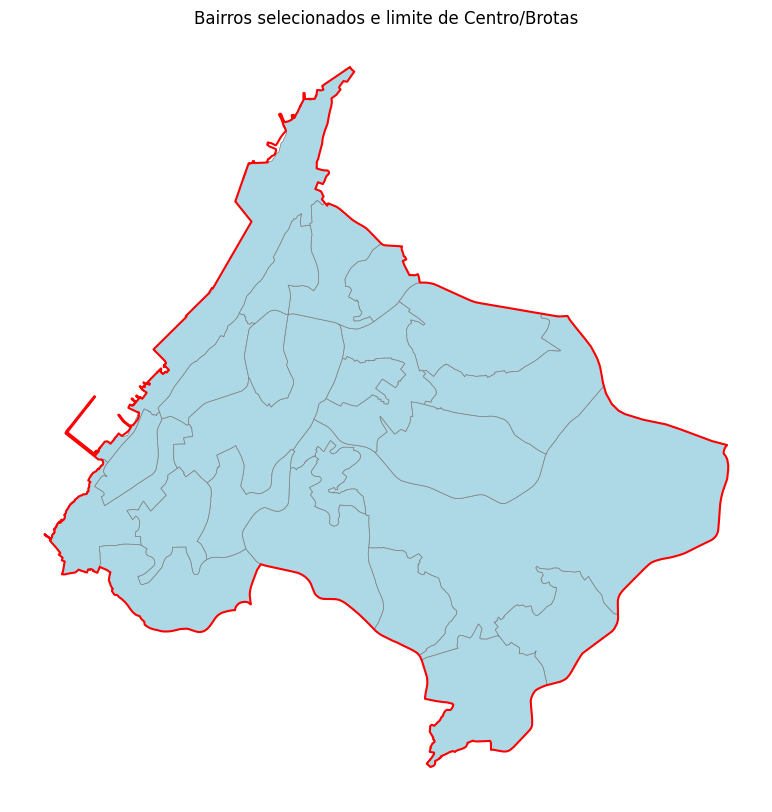

In [73]:
fig, ax = plt.subplots(figsize=(10, 10))

bairros_piloto.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="gray",
    linewidth=0.5
)

piloto.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

ax.set_title("Bairros selecionados e limite de Centro/Brotas")
ax.set_axis_off()

plt.show()

In [71]:
conferencia = bairros_piloto[["NOME_BAIRRO"]].copy()

conferencia["area_fora_m2"] = (
    bairros_piloto.geometry
    .difference(limite_piloto)
    .area
)

print(
    conferencia.sort_values("area_fora_m2", ascending=False)
    .head(5)
    .to_string(index=False, float_format=lambda valor: f"{valor:.2f}")
)

    NOME_BAIRRO  area_fora_m2
       Comércio       6030.27
         Centro       2257.70
Horto Florestal          0.24
         Brotas          0.04
         Garcia          0.02


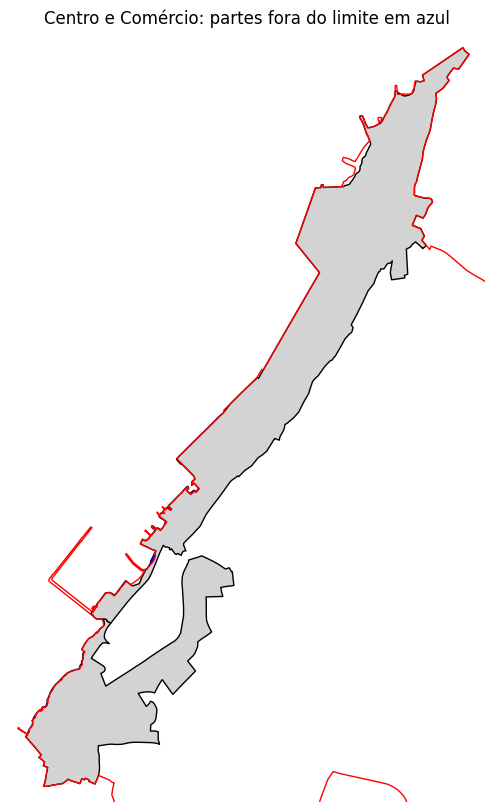

In [75]:
comparacao = bairros_piloto.loc[
    bairros_piloto["NOME_BAIRRO"].isin(["Centro", "Comércio"])
].copy()

partes_fora = comparacao.geometry.difference(limite_piloto)

fig, ax = plt.subplots(figsize=(10, 10))

comparacao.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="black"
)

piloto.boundary.plot(ax=ax, color="red", linewidth=1)
partes_fora.plot(ax=ax, color="blue")

# Limita a visualização à região dos dois bairros
xmin, ymin, xmax, ymax = comparacao.total_bounds
ax.set_xlim(xmin - 100, xmax + 100)
ax.set_ylim(ymin - 100, ymax + 100)

ax.set_title("Centro e Comércio: partes fora do limite em azul")
ax.set_axis_off()

plt.show()

O território-piloto será definido pela geometria da Prefeitura-Bairro I — Centro/Brotas. A seleção provisória dos 23 bairros será utilizada para contextualização e organização dos resultados. As diferenças entre os limites das bases foram registradas, sem alterações nos dados originais.